# UTS Deep Learning: Fitur Unik & Unit Test (Anggota 4, bagian 2)
Model final: **A3_reg_saja** (MobileNetV2 + regularisasi), dipilih dari akurasi *validation* tertinggi.

## Tambahan file di Google Drive
Upload **3 file baru** ini ke folder `My Drive/UTS_DeepLearning/` (file lama tetap di tempatnya):

```
UTS_DeepLearning/
├── inferensi.py        (BARU)
├── fitur_unik.py       (BARU)
├── test_sampah.py      (BARU)
├── ... file lama (CNN_Sampah.py, evaluasi_model.py, eksperimen_perbaikan.py, dataset zip, cnn_training_output/)
└── hasil_eksperimen/   (sudah ada, berisi A3_reg_saja/best_model.keras)
```

## Cara pakai
1. **Runtime → Change runtime type → T4 GPU**.
2. Pilih **Runtime → Run all**. Total waktu sekitar 10–20 menit.
   Hasil tersimpan di `My Drive/UTS_DeepLearning/hasil_fitur_unik/` dan `model_final/`.

## Langkah 1: Cek GPU

In [ ]:
import tensorflow as tf
gpu = tf.config.list_physical_devices("GPU")
print("TensorFlow:", tf.__version__)
print("GPU:", gpu if gpu else "TIDAK ADA. Aktifkan di Runtime > Change runtime type > T4 GPU")
!nvidia-smi -L

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU 0: Tesla T4 (UUID: GPU-95574aea-18a2-4738-b378-9a4c45ac9b05)


## Langkah 2: Hubungkan Google Drive & cek file

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
DRIVE_DIR = Path("/content/drive/MyDrive/deep_learning")

wajib = [
    "CNN_Sampah.py",
    "evaluasi_model.py",
    "eksperimen_perbaikan.py",
    "datasett_preprocessed.zip",
    "cnn_training_output/best_cnn_sampah.keras",
    "cnn_training_output/training_log.csv",
    "inferensi.py",
    "fitur_unik.py",
    "test_sampah.py",
    "hasil_eksperimen/A3_reg_saja/best_model.keras",
]
kurang = [f for f in wajib if not (DRIVE_DIR / f).exists()]
for f in wajib:
    print(("OK      " if f not in kurang else "TIDAK ADA ") + f)
if kurang:
    raise FileNotFoundError(f"Upload dulu file berikut ke {DRIVE_DIR}: {kurang}")
print("\nSemua file lengkap.")

Mounted at /content/drive
OK      CNN_Sampah.py
OK      evaluasi_model.py
OK      eksperimen_perbaikan.py
OK      datasett_preprocessed.zip
OK      cnn_training_output/best_cnn_sampah.keras
OK      cnn_training_output/training_log.csv
OK      inferensi.py
OK      fitur_unik.py
OK      test_sampah.py
OK      hasil_eksperimen/A3_reg_saja/best_model.keras

Semua file lengkap.


## Langkah 3: Siapkan folder kerja

In [ ]:
import os, shutil, zipfile

PROJ = Path("/content/proj")
PROJ.mkdir(exist_ok=True)

# 1) salin skrip & output Anggota 3 (selalu disalin ulang agar versi terbaru dari Drive terpakai)
for f in DRIVE_DIR.glob("*.py"):          # semua skrip .py di folder Drive
    shutil.copy(f, PROJ / f.name)
shutil.copytree(DRIVE_DIR / "cnn_training_output", PROJ / "cnn_training_output", dirs_exist_ok=True)

# Perbaikan otomatis: pastikan evaluasi_model.py bisa membuka model dari versi Keras berbeda
_FUNGSI = '''
def muat_model(path):
    try:
        return tf.keras.models.load_model(str(path), compile=False)
    except (TypeError, ValueError):
        print("[INFO] Versi Keras berbeda. Membangun ulang arsitektur dari CNN_Sampah.build_cnn() dan memuat bobotnya...")
        _, _, _, class_names = base.collect_splits(base.DATASET_DIR)
        model = base.build_cnn(num_classes=len(class_names))
        model.load_weights(str(path))
        print("[INFO] Bobot berhasil dimuat.")
        return model


def main() -> None:'''
_p = PROJ / "evaluasi_model.py"
_s = _p.read_text(encoding="utf-8")
if "def muat_model" not in _s:
    _s = _s.replace("\ndef main() -> None:", _FUNGSI, 1)
    _s = _s.replace("model = tf.keras.models.load_model(args.model, compile=False)", "model = muat_model(args.model)", 1)
    _p.write_text(_s, encoding="utf-8")

# 2) ekstrak dataset (hanya jika belum)
DATA = PROJ / "datasett_preprocessed"
if not DATA.exists():
    tmp = Path("/content/_ekstrak")
    print("Mengekstrak dataset... (1-3 menit)")
    with zipfile.ZipFile(DRIVE_DIR / "datasett_preprocessed.zip") as z:
        z.extractall(tmp)
    # cari folder yang berisi folder-folder kelas (menangani ZIP bertingkat)
    kandidat = [p for p in [tmp, *tmp.rglob("*")] if p.is_dir()
                and sum(1 for c in p.iterdir() if c.is_dir()) >= 5
                and not any(c.is_file() for c in p.iterdir())]
    sumber = min(kandidat, key=lambda p: len(p.parts))
    shutil.move(str(sumber), str(DATA))
    shutil.rmtree(tmp, ignore_errors=True)

# 3) hasil_eksperimen -> Google Drive
HASIL_DRIVE = DRIVE_DIR / "hasil_eksperimen"
HASIL_DRIVE.mkdir(exist_ok=True)
for nama in ["hasil_eksperimen", "hasil_fitur_unik", "model_final"]:   # semua hasil -> Google Drive
    (DRIVE_DIR / nama).mkdir(exist_ok=True)
    link = PROJ / nama
    if not link.exists():
        os.symlink(DRIVE_DIR / nama, link)

os.chdir(PROJ)
print("Folder kerja :", PROJ)
print("Kelas        :", sorted(p.name for p in DATA.iterdir() if p.is_dir()))
print("Hasil disimpan ke:", HASIL_DRIVE)

Mengekstrak dataset... (1-3 menit)
Folder kerja : /content/proj
Kelas        : ['Food Organics', 'Miscellaneous Trash', 'Plastic', 'Textile Trash', 'Vegetation', 'cardboard', 'glass', 'metal', 'paper', 'trash']
Hasil disimpan ke: /content/drive/MyDrive/deep_learning/hasil_eksperimen


In [ ]:
!pip -q install pytest
from IPython.display import Image, display, Markdown
OOD_FOLDER = DRIVE_DIR / "foto_bukan_sampah"
print("Folder foto bukan sampah:", "ADA" if OOD_FOLDER.is_dir() else "tidak ada (hanya memakai CIFAR-10)")

Folder foto bukan sampah: tidak ada (hanya memakai CIFAR-10)


---
## Bagian A: Bukti dampak 5 fitur unik
Menjalankan `fitur_unik.py`: melatih A5 (tanpa class weight, ± 3 menit), lalu F1–F5. Perkiraan total 10–15 menit.

In [ ]:
arg = f'--ood-folder "{OOD_FOLDER}"' if OOD_FOLDER.is_dir() else ""
!python fitur_unik.py {arg}


MELATIH A5: sama dengan A3, hanya TANPA class weight (± 2-5 menit dengan GPU)

########################################################################
# EKSPERIMEN A5_reg_tanpa_class_weight
# Ablasi: MobileNetV2 beku, regularisasi, TANPA class weight
########################################################################
W0000 00:00:1793299840.173245    2982 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Model: "tl_mobilenetv2"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ ke_rentang_min1_1 (Re

### Hasil per fitur

In [ ]:
H = PROJ / "hasil_fitur_unik"
for f, judul in [
    ("F1_gradcam_perbandingan.png", "F1. Grad-CAM: baseline vs model final"),
    ("F2_class_weight_recall.png", "F2. Class weight vs tanpa class weight"),
    ("F3_confidence_threshold.png", "F3. Confidence threshold"),
    ("F4_ood_histogram.png", "F4. Deteksi luar domain: sebaran skor"),
    ("F4_contoh_ood.png", "F4. Contoh gambar bukan sampah"),
    ("F5_tflite.png", "F5. Kompresi TFLite"),
]:
    display(Markdown(f"#### {judul}"))
    if (H / f).exists():
        display(Image(filename=str(H / f), width=1100))
    else:
        print("(belum ada)")
display(Markdown(open(H / "ringkasan_fitur_unik.md", encoding="utf-8").read()))

Output hidden; open in https://colab.research.google.com to view.

---
## Bagian B: Unit test
Semua test harus **PASSED**. Hasil disimpan ke `hasil_fitur_unik/hasil_unit_test.txt` sebagai bukti untuk laporan.

In [ ]:
!python -m pytest test_sampah.py -v 2>&1 | tee hasil_fitur_unik/hasil_unit_test.txt

============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/proj
plugins: platformdirs-4.13.5, langsmith-0.14.12, anyio-4.15.1, typeguard-4.6.0
collecting ... collected 22 items

test_sampah.py::test_split_tidak_ada_kebocoran PASSED                    [  4%]
test_sampah.py::test_split_reprodusibel PASSED                           [  9%]
test_sampah.py::test_split_sama_dengan_baseline PASSED                   [ 13%]
test_sampah.py::test_proporsi_split_80_10_10 PASSED                      [ 18%]
test_sampah.py::test_preprocess_bentuk_dan_rentang PASSED                [ 22%]
test_sampah.py::test_preprocess_menerima_berbagai_input PASSED           [ 27%]
test_sampah.py::test_preprocess_identik_dengan_training PASSED           [ 31%]
test_sampah.py::test_class_weight_kelas_minoritas_terbesar PASSED        [ 36%]
test_sampah.py::test_tentukan_status[

---
## Bagian C: Perbarui tabel perbandingan (sekarang termasuk A5)

| Eksperimen | Akurasi test | Macro F1 | Top-3 | Δ akurasi vs baseline | Keterangan |
|---|---|---|---|---|---|
| A1_tanpa_aug_tanpa_reg | 0.8391 | 0.8243 | 0.9787 | +28.5 poin | Ablasi: MobileNetV2 beku, tanpa augmentasi, tanpa regularisasi |
| A2_aug_saja | 0.8062 | 0.7777 | 0.9767 | +25.2 poin | Ablasi: MobileNetV2 beku, augmentasi saja |
| A3_reg_saja | 0.8333 | 0.8175 | 0.9806 | +27.9 poin | Ablasi: MobileNetV2 beku, regularisasi saja |
| A4_aug_dan_reg | 0.8159 | 0.7919 | 0.9690 | +26.2 poin | Ablasi: MobileNetV2 beku, augmentasi + regularisasi |
| A5_reg_tanpa_class_weight | 0.8256 | 0.8029 | 0.9748 | +27.1 poin | Ablasi: MobileNetV2 beku, regularisasi, TANPA class weight |
| E0_baseline | 0.5543 | 0.5411 | 0.8818 | +0.0 poin | CNN 4 blok dari nol (model Anggota 3) |
| E1_cnn_stabil | 0.6609 | 0.6392 | 0.8779 | +10.7 poin | CNN baseline + AdamW, warmup-cosine LR 5e-4, BN momentum 0.9, label smoothing 0.1, augmentasi kuat |
| E2_mobilenetv2 | 0.8275 | 0.8111 | 0.9748 | +27.3 poin

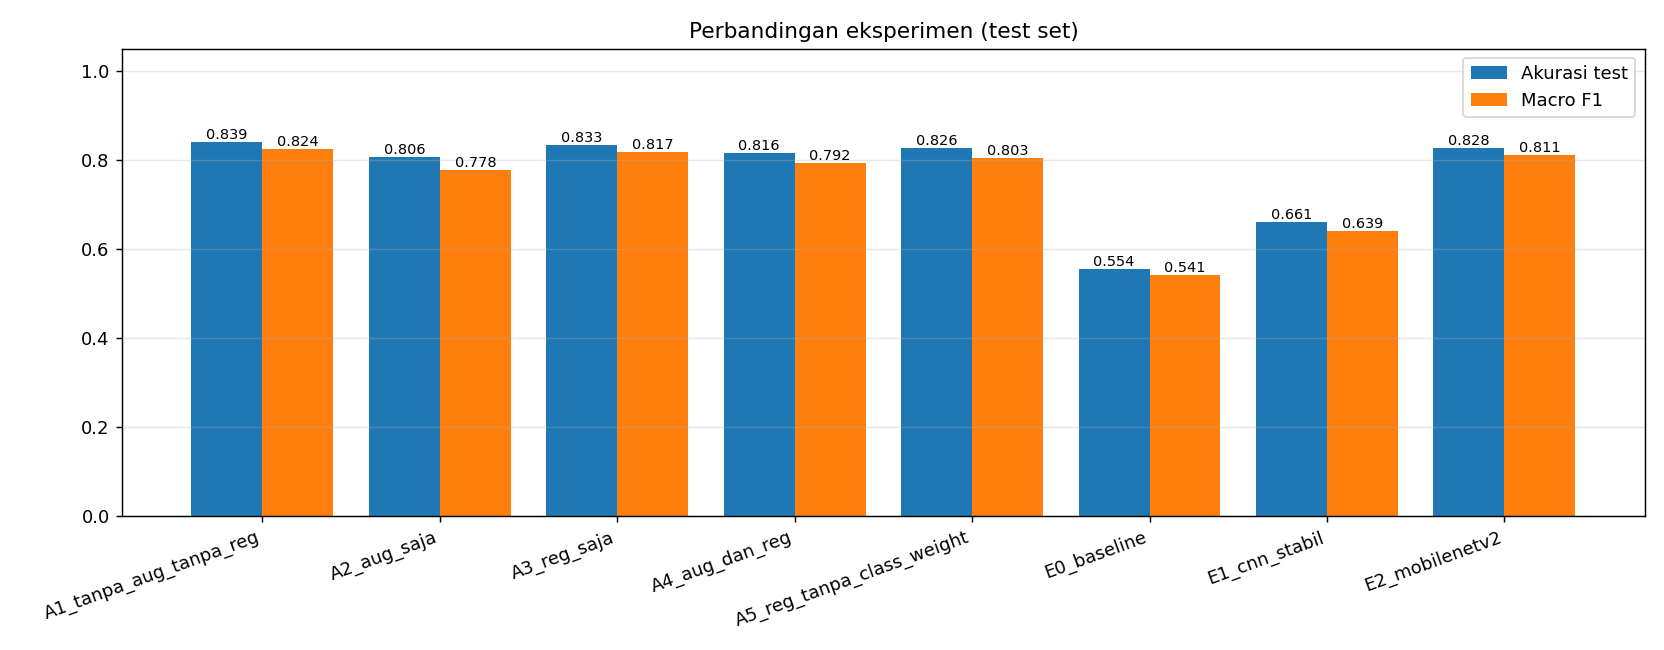

In [ ]:
!python eksperimen_perbaikan.py --ringkasan
display(Image(filename="hasil_eksperimen/perbandingan_eksperimen.png", width=1000))

---
## Bagian D: Coba prediksi satu gambar (seperti aplikasi nanti)
Ganti `contoh` dengan path gambar lain jika mau, misalnya foto yang di-upload ke Drive.

Label asli : cardboard
Prediksi   : cardboard (0.75)
Top-3      : [('cardboard', 0.748), ('Miscellaneous Trash', 0.129), ('Textile Trash', 0.046)]
Status     : di_luar_domain - Gambar tampaknya bukan foto sampah sehingga tidak diklasifikasikan.


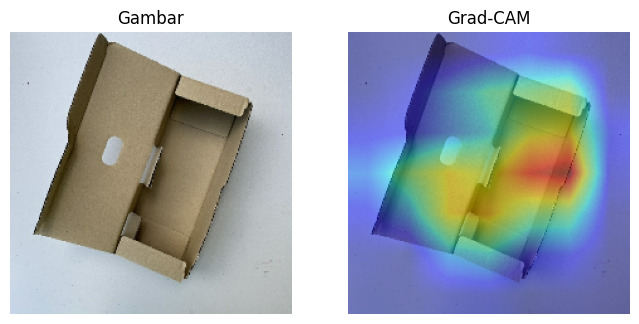

In [ ]:
import sys, matplotlib.pyplot as plt
sys.path.insert(0, str(PROJ))
import CNN_Sampah as base
from inferensi import PrediktorSampah, muat_gambar
p = PrediktorSampah.dari_folder(PROJ / "model_final")
_, _, test, kelas = base.collect_splits(base.DATASET_DIR)
contoh = test[7][0]                       # path gambar
hasil = p.prediksi(contoh)
print("Label asli :", kelas[test[7][1]])
print("Prediksi   :", hasil["label"], f"({hasil['keyakinan']:.2f})")
print("Top-3      :", [(k, round(v, 3)) for k, v in hasil["top_k"]])
print("Status     :", hasil["status"], "-", hasil["pesan"])
img = muat_gambar(contoh)
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(img); ax[0].set_title("Gambar"); ax[0].axis("off")
ax[1].imshow(img); ax[1].imshow(p.gradcam(img), cmap="jet", alpha=0.45); ax[1].set_title("Grad-CAM"); ax[1].axis("off")
plt.show()

---
## (Opsional) Unduh hasil sebagai ZIP

In [ ]:
for nama in ["hasil_fitur_unik", "model_final"]:
    shutil.make_archive(f"/content/{nama}", "zip", root_dir=str(DRIVE_DIR / nama))
from google.colab import files
files.download("/content/hasil_fitur_unik.zip")
files.download("/content/model_final.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip -q install gradio
!python app.py

W0000 00:00:1793493514.013972    4022 gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was false.
* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://c88579d2e10425999c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
